In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [ ]:
#Define entropy, Gini impurity and information gain
def calculate_entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()

    return -np.sum(probabilities * np.log2(probabilities))


def calculate_gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()

    return 1 - np.sum(probabilities ** 2)


def calculate_information_gain(parent, left, right):
    total = len(parent)

    child_entropy = (
        len(left) / total * calculate_entropy(left)
        + len(right) / total * calculate_entropy(right)
    )

    return calculate_entropy(parent) - child_entropy

In [ ]:
#Calculate the splitting criteria manually
parent = np.array([0, 0, 0, 1, 1, 1])
left = np.array([0, 0, 0])
right = np.array([1, 1, 1])

criteria_table = pd.DataFrame({
    "Measure": [
        "Entropy",
        "Gini Impurity",
        "Information Gain"
    ],
    "Value": [
        calculate_entropy(parent),
        calculate_gini(parent),
        calculate_information_gain(parent, left, right)
    ]
})

criteria_table.round(4)

,Measure,Value
0,Entropy,1.0
1,Gini Impurity,0.5
2,Information Gain,1.0


In [ ]:
#Load the dataset
wine_data = load_wine(as_frame=True)

X = wine_data.data
y = wine_data.target

print(X.head())
print("\nTarget classes:", list(wine_data.target_names))
print("Dataset shape:", X.shape)

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

In [ ]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Classes:", list(wine_data.target_names))

Training samples: 142
Testing samples: 36
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


In [ ]:
#Train decision trees using Gini and entropy
tree_models = {
    "Gini Impurity": DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42
    ),

    "Entropy / Information Gain": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        random_state=42
    )
}

model_results = []
predictions = {}

for name, tree in tree_models.items():
    tree.fit(X_train, y_train)

    predicted = tree.predict(X_test)
    predictions[name] = predicted

    model_results.append({
        "Criterion": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "F1 Score": f1_score(y_test, predicted, average="weighted"),
        "Depth": tree.get_depth(),
        "Leaves": tree.get_n_leaves()
    })

results_table = pd.DataFrame(model_results).set_index("Criterion")

results_table.round(4)

,Accuracy,F1 Score,Depth,Leaves
Criterion,,,,
Gini Impurity,0.9444,0.945,4,8
Entropy / Information Gain,0.9722,0.972,4,8


In [ ]:
#Classification report
print(
    classification_report(
        y_test,
        predictions["Entropy / Information Gain"],
        target_names=wine_data.target_names
    )
)

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



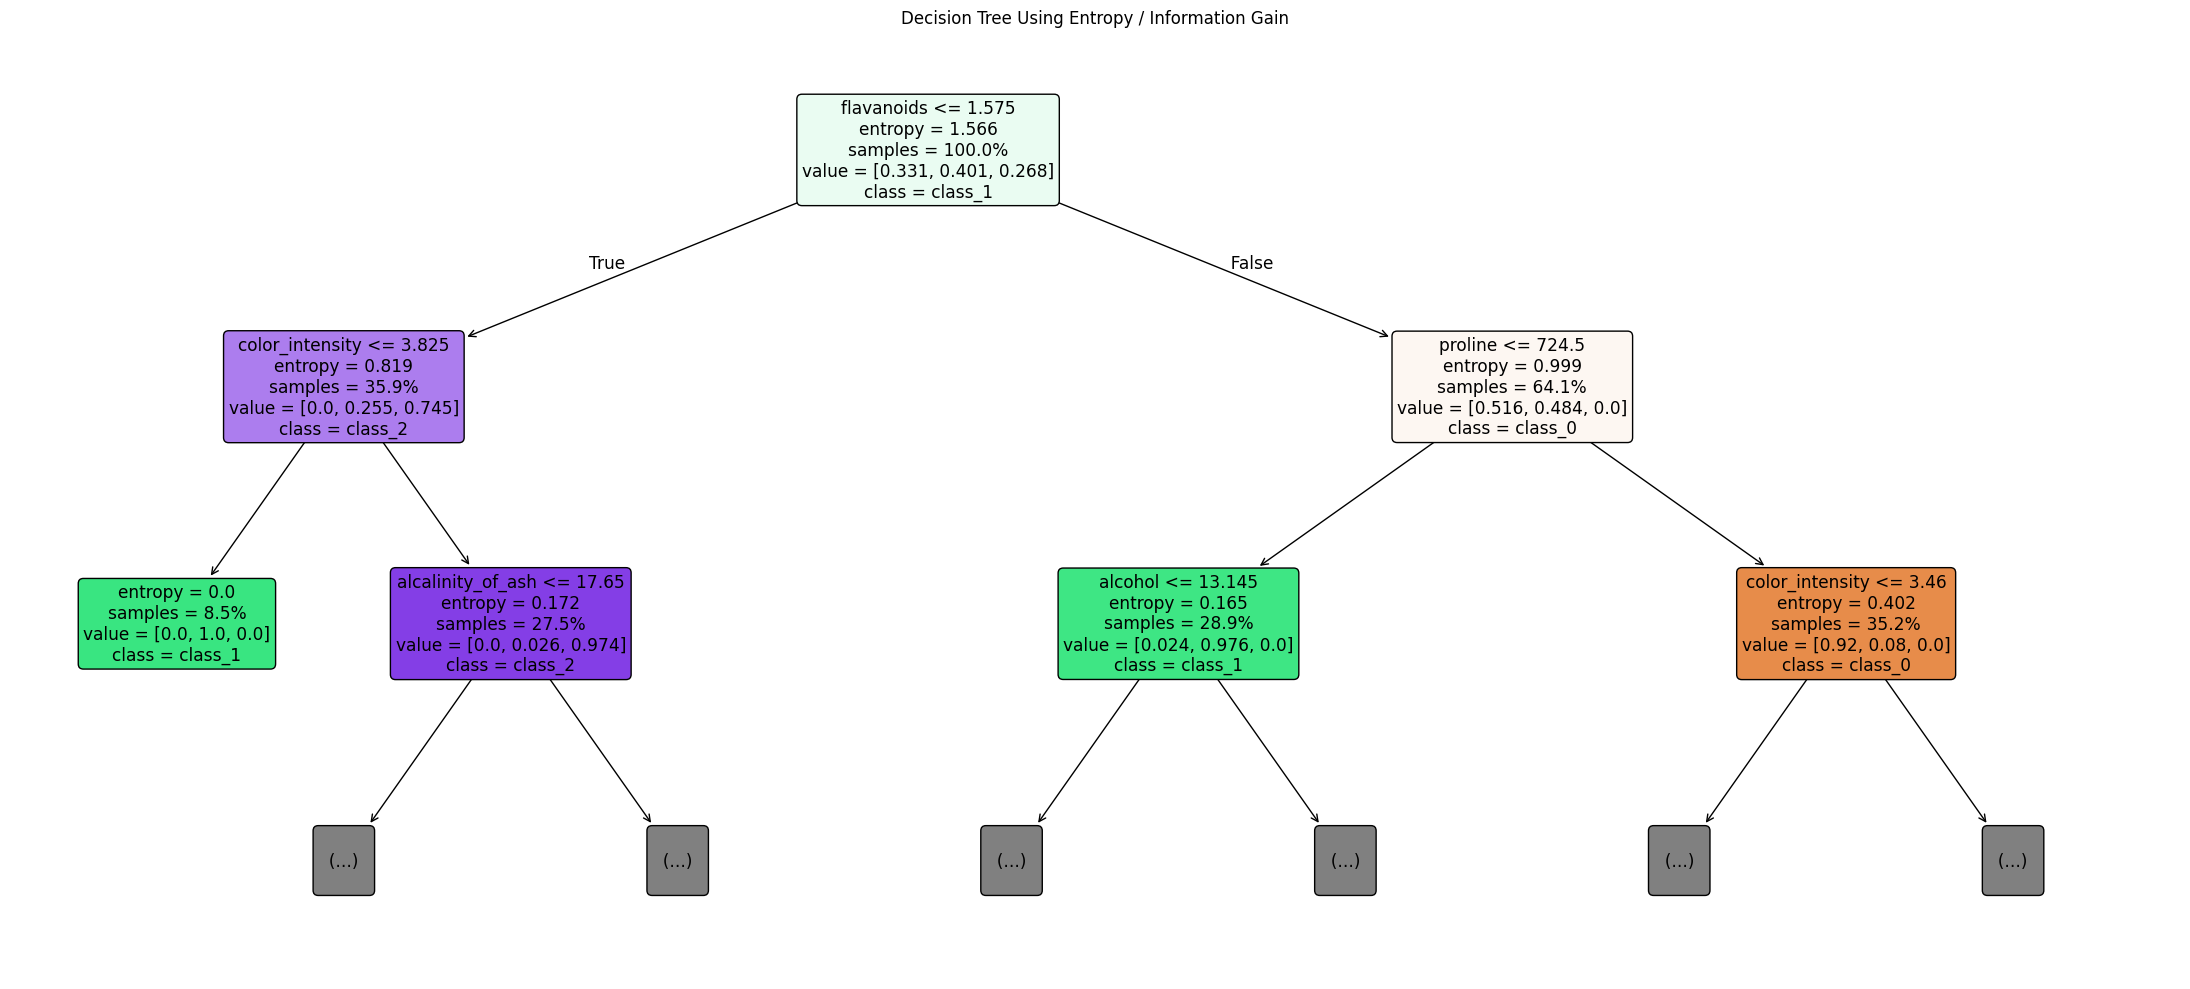

In [ ]:
#Visualize the decision tree
plt.figure(figsize=(22, 10))

plot_tree(
    tree_models["Entropy / Information Gain"],
    feature_names=X.columns,
    class_names=wine_data.target_names,
    filled=True,
    max_depth=2,
    proportion=True,
    rounded=True
)

plt.title("Decision Tree Using Entropy / Information Gain")
plt.tight_layout()
plt.show()